In [92]:
#Beginning pseudospectral coding stuff
import numpy as np
import matplotlib.pyplot as plt

#TRANSFORMATION PROCESS:
    #Physical Space: u and q --> Values at each position along the pipe
    #Fourier Space: uh and qh --> Fourier coefficients representing the spatial patterns
    #Physical Space: u and q --> Can then put into physical equations

#Parameters for model
zeta = 0.8
eta = 0 #unsure how to implement, not necessary if sigma is 0
D = 0.5
delta = 0.1
e_1 = 0.1
e_2 = 0.2
sigma = 0
U_dash, U_0 = 1, 2 
r_value = 0.9
save_every = 10

if sigma!=0:
    print("sigma not equal to 0, check eta value.")

#Parameters for pseudospectral methods
L, N = 250/2, 256
l = 1
x = np.linspace(0, L, N, endpoint=False)    #ensures that we don't count the same point twice given the periodic boundary conditions
dt, T = 0.05, 250
k = 2*np.pi * np.fft.fftfreq(N, d=L/N)      #gives wavenumbers
ik = 1j*k                                   #writing out ik in python terms --> this is an array of imaginary numbers
ik[N//2] = 0                                #making the derivative real and uniquely defined as odd-derivatives are anti-symmetric here
                                            # we are zeroing the nyquist mode (setting to 0)
dealias = np.abs(k) < (2/3) * np.abs(k).max()  #2/3 rule
nsteps = int(round(T/dt))

#Initialisation
u0 = np.ones(N)*2
#u0 = np.ones(N)*1.262694211143976
q0 = 1.5*np.exp(-((x - L/2)**2)/(l**2))
#q0 = np.ones(N)*1.4033537047604092
uh, qh = np.fft.fft(u0)*dealias, np.fft.fft(q0)*dealias #transforming into fourier space + dealiasing (remove the false errors)

def rhs(uh, qh, r):
    #(1): Back to grid space for the non-linear terms
    u, q = np.fft.ifft(uh).real, np.fft.ifft(qh).real
    ux, qx, = np.fft.ifft(ik * uh).real, np.fft.ifft(ik * qh).real #spectrally computed derivatives 
    qxx = np.fft.ifft(-k**2 * qh).real

    #(2): Defining f and g and Method Of Lines terms 
    f = q*(r + u - U_0 - (r + delta)*(q - 1)**2)
    g = e_1*(U_0 - u) + e_2*(U_dash - u)*q

    du_rhs = g - u*ux
    dq_rhs = f + D*qxx + sigma*q*eta - (u - zeta)*qx

    duh = np.fft.fft(du_rhs) * dealias
    dqh = np.fft.fft(dq_rhs) * dealias

    return duh, dqh

def rk4_step(uh, qh, dt, r):
    k1u, k1q = rhs(uh, qh, r)
    k2u, k2q = rhs(uh + 0.5*dt*k1u, qh + 0.5*dt*k1q, r)
    k3u, k3q = rhs(uh + 0.5*dt*k2u, qh + 0.5*dt*k2q, r)
    k4u, k4q = rhs(uh + dt*k3u, qh + dt*k3q, r)
    uh = uh + dt/6*(k1u + 2*k2u + 2*k3u + k4u)
    qh = qh + dt/6*(k1q + 2*k2q + 2*k3q + k4q)

    return uh, qh

u_series = []
q_series = []
t_series = []

uh1 = uh.copy()
qh1 = qh.copy()

for n in range(nsteps):
    uh, qh = rk4_step(uh, qh, dt, r_value)
    u, q = np.fft.ifft(uh).real, np.fft.ifft(qh).real
    
    if (n+1) % save_every == 0:
        u_series.append(u.copy())
        q_series.append(q.copy())
        t_series.append((n+1)*dt)

#if np.array_equal(uh1, uh) or np.array_equal(qh1, qh):
    #print("ERROR")

u_series = np.stack(u_series)
q_series = np.stack(q_series)
t_series = np.array(t_series)


In [93]:
print(k)

[ 0.          0.05026548  0.10053096  0.15079645  0.20106193  0.25132741
  0.30159289  0.35185838  0.40212386  0.45238934  0.50265482  0.55292031
  0.60318579  0.65345127  0.70371675  0.75398224  0.80424772  0.8545132
  0.90477868  0.95504417  1.00530965  1.05557513  1.10584061  1.1561061
  1.20637158  1.25663706  1.30690254  1.35716803  1.40743351  1.45769899
  1.50796447  1.55822996  1.60849544  1.65876092  1.7090264   1.75929189
  1.80955737  1.85982285  1.91008833  1.96035382  2.0106193   2.06088478
  2.11115026  2.16141575  2.21168123  2.26194671  2.31221219  2.36247768
  2.41274316  2.46300864  2.51327412  2.56353961  2.61380509  2.66407057
  2.71433605  2.76460154  2.81486702  2.8651325   2.91539798  2.96566346
  3.01592895  3.06619443  3.11645991  3.16672539  3.21699088  3.26725636
  3.31752184  3.36778732  3.41805281  3.46831829  3.51858377  3.56884925
  3.61911474  3.66938022  3.7196457   3.76991118  3.82017667  3.87044215
  3.92070763  3.97097311  4.0212386   4.07150408  4.1

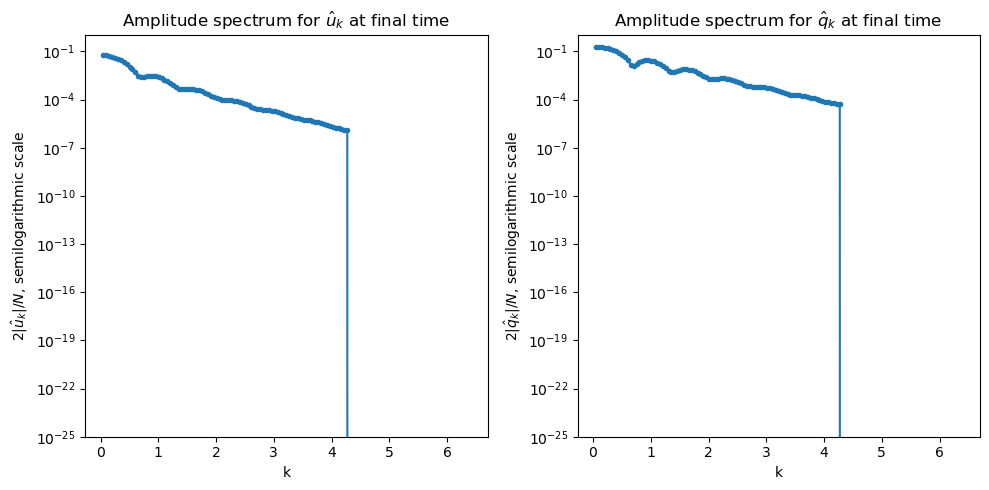

In [94]:
half = slice(1, N//2) #positive wavenumbers only (don't need duplicates)

fig, ax = plt.subplots(1, 2, figsize = (10,5))
ax[0].semilogy(k[half], 2*np.abs(uh[half]/N), marker='o', ms=3)
ax[0].set_xlabel("k")
ax[0].set_ylabel(r"$2|\hat u_k|/N$, semilogarithmic scale")
ax[0].set_title(r"Amplitude spectrum for $\hat u_k$ at final time ")
ax[0].set_ylim(1e-25, 1)

ax[1].semilogy(k[half], 2*np.abs(qh[half]/N), marker='o', ms=3)
ax[1].set_xlabel("k")
ax[1].set_ylabel(r"$2|\hat q_k|/N$, semilogarithmic scale")
ax[1].set_title(r"Amplitude spectrum for $\hat q_k$ at final time ")
ax[1].set_ylim(1e-25, 1)

plt.tight_layout()
plt.show()

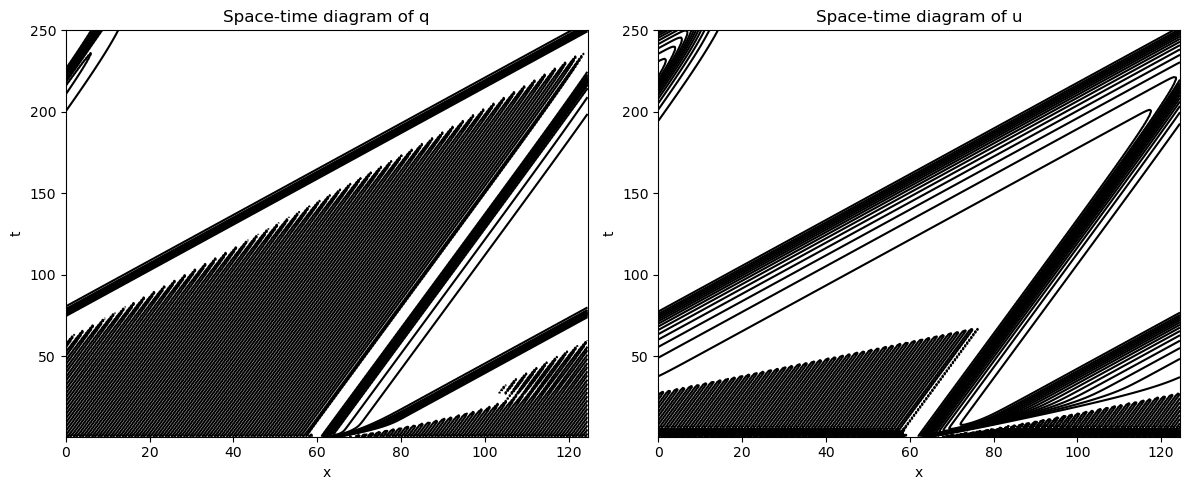

In [95]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].contour(x, t_series, q_series, levels=15,colors='black')
ax[0].set_xlabel('x')
ax[0].set_ylabel('t')
ax[0].set_title('Space-time diagram of q')

ax[1].contour(x, t_series, u_series, levels=15, colors='black')

ax[1].set_xlabel('x')
ax[1].set_ylabel('t')
ax[1].set_title('Space-time diagram of u')

plt.tight_layout()
plt.show()

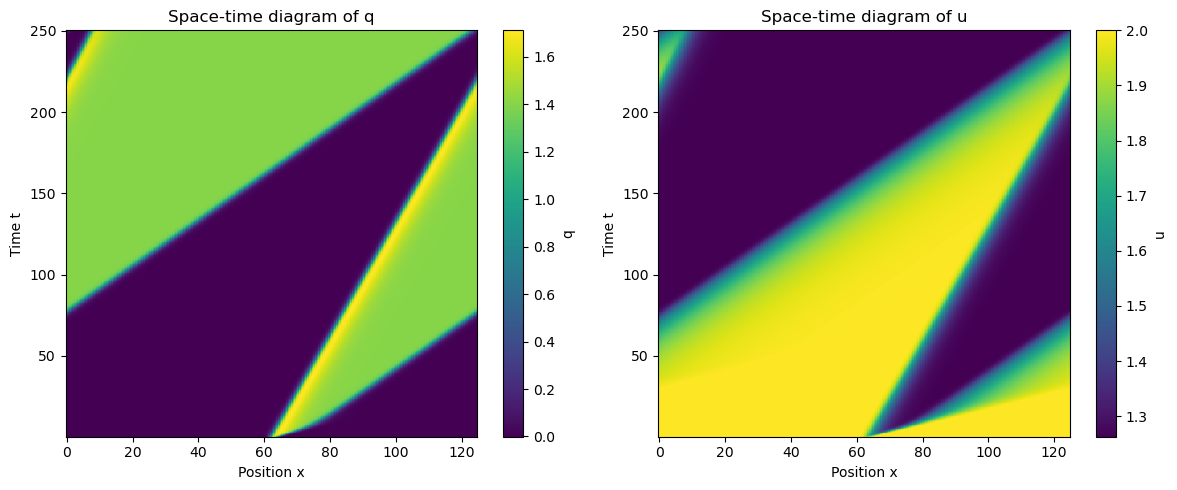

In [96]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Space-time diagram of q
mesh1 = ax[0].pcolormesh(
    x, t_series, q_series,
    shading='auto',
    cmap='viridis'
)

ax[0].set_xlabel('Position x')
ax[0].set_ylabel('Time t')
ax[0].set_title('Space-time diagram of q')

fig.colorbar(mesh1, ax=ax[0], label='q')

# Space-time diagram of u
mesh2 = ax[1].pcolormesh(
    x, t_series, u_series,
    shading='auto',
    cmap='viridis'
)

ax[1].set_xlabel('Position x')
ax[1].set_ylabel('Time t')
ax[1].set_title('Space-time diagram of u')

fig.colorbar(mesh2, ax=ax[1], label='u')

plt.tight_layout()
plt.show()

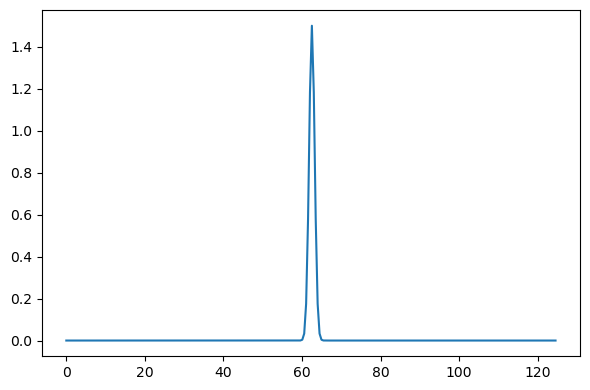

In [97]:
fig, ax = plt.subplots(1, 1,  figsize=(6,4))

ax.plot(x, q0)

plt.tight_layout()
plt.show()


In [98]:
#started running for multiple r 
def run_simulation(r):

    # Start from the same initial conditions each time
    uh = np.fft.fft(u0) * dealias
    qh = np.fft.fft(q0) * dealias

    u_series = []
    q_series = []
    t_series = []

    for n in range(nsteps):
        uh, qh = rk4_step(uh, qh, dt, r)

        if (n+1) % save_every == 0:
            u = np.fft.ifft(uh).real
            q = np.fft.ifft(qh).real

            u_series.append(u.copy())
            q_series.append(q.copy())
            t_series.append((n+1)*dt)

    return (np.stack(u_series), np.stack(q_series),np.array(t_series))

r_values = [0.3, 0.6, 0.9]
results = {}

for i in r_values:
    results[i] = run_simulation(i) #run simulation for each r


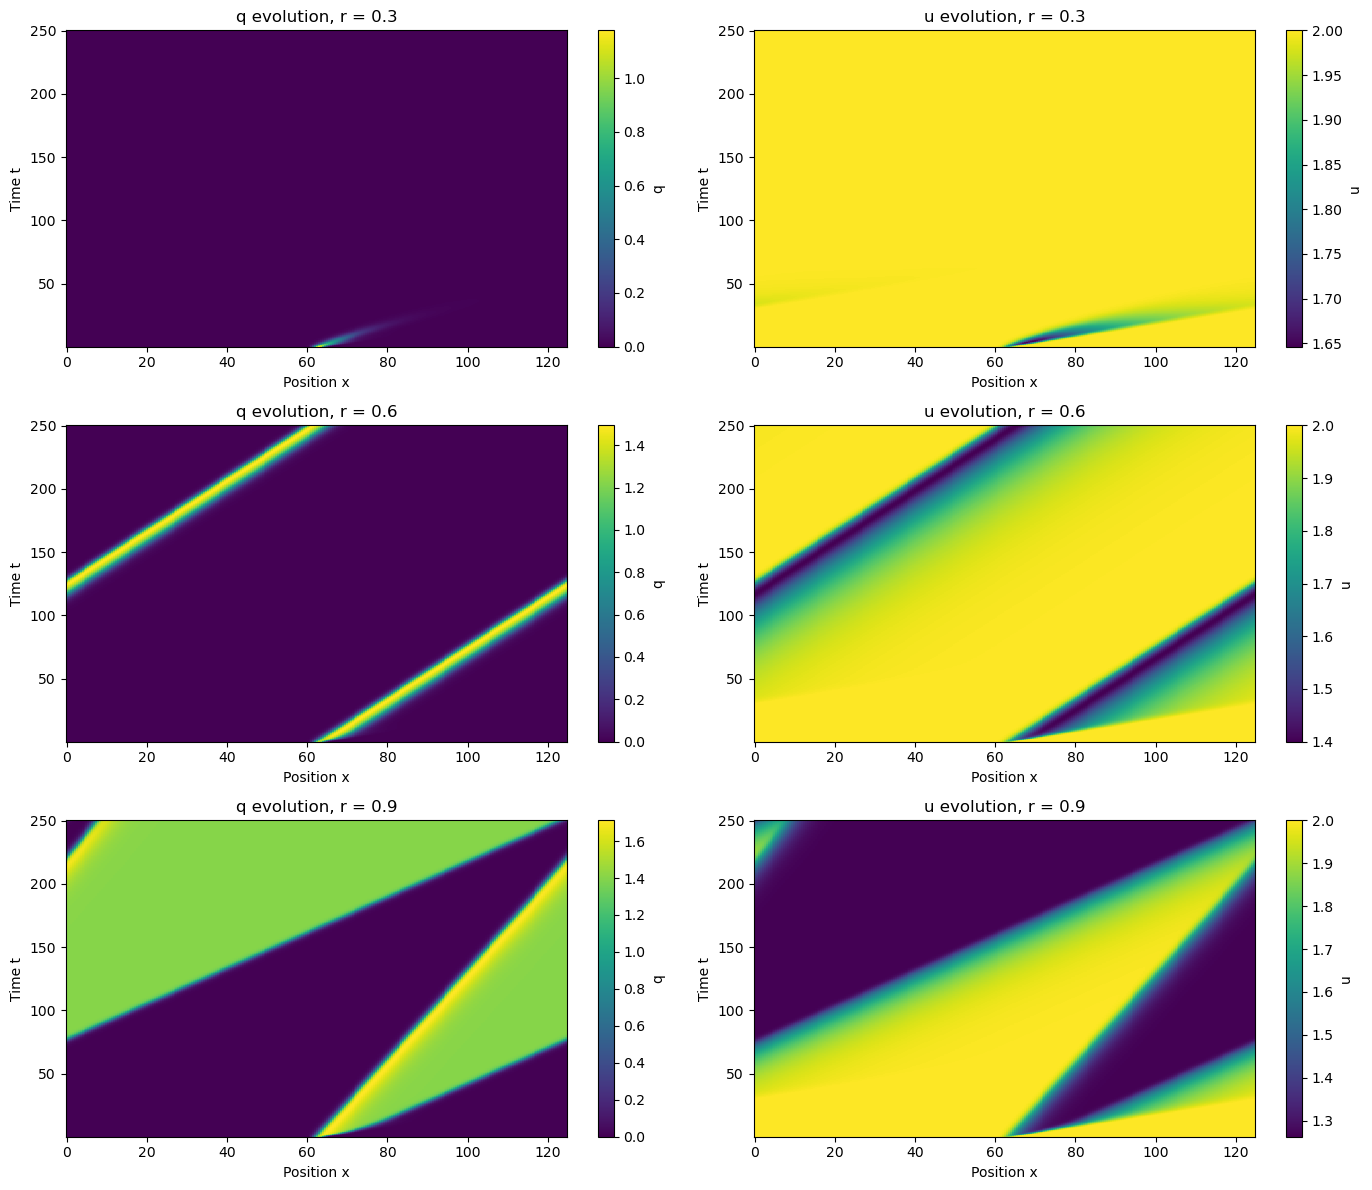

In [101]:
#Total plot of different r values, probably best to mainly use this
fig, ax = plt.subplots(len(r_values), 2, figsize=(14, 12))

for idx, r in enumerate(r_values):
    u_data, q_data, times = results[r]

    # Left column: q
    mesh1 = ax[idx, 0].pcolormesh(x, times, q_data)
    #ax[idx, 0].contour(x, times, q_data, levels=15,colors='black')
    ax[idx, 0].set_title(f'q evolution, r = {r}')
    ax[idx, 0].set_xlabel('Position x')
    ax[idx, 0].set_ylabel('Time t')
    fig.colorbar(mesh1, ax=ax[idx, 0], label='q')

    # Right column: u
    mesh2 = ax[idx, 1].pcolormesh(x, times, u_data)
    #ax[idx, 1].contour(x, times, u_data, levels=15,colors='black')
    ax[idx, 1].set_title(f'u evolution, r = {r}')
    ax[idx, 1].set_xlabel('Position x')
    ax[idx, 1].set_ylabel('Time t')
    fig.colorbar(mesh2, ax=ax[idx, 1], label='u')

plt.tight_layout()
plt.show()

- look at velocities of puffs and slugs
- looking at top figure of fig 19
- up to and including 9.6
- 